# 🌟 ALGORITHMS SUPPORTING BOTH CLASSIFICATION AND REGRESSION
## Comprehensive Theory, Visualizations, Hands-on Code & 100% Interview Mastery

Many foundational supervised learning algorithms are inherently dual-purpose. They are not restricted to just classification or regression, but adapt their mathematical criteria, cost functions, and prediction logic to handle discrete categories or continuous values.

### Algorithms Covered in Depth:
1. **K-Nearest Neighbors (KNN)**: `KNeighborsClassifier` vs `KNeighborsRegressor`
2. **Decision Trees**: `DecisionTreeClassifier` vs `DecisionTreeRegressor`
3. **Support Vector Machines (SVM)**: `SVC` (Classification) vs `SVR` (Regression)
4. **Random Forest & Ensemble Methods**: `RandomForestClassifier` vs `RandomForestRegressor`
5. **Gradient Boosting**: `GradientBoostingClassifier` vs `GradientBoostingRegressor`
6. **Side-by-Side Comparison Matrix** (Split criteria, loss functions, extrapolation limits, complexities)
7. **Top 25 High-Yield Interview Questions & Expert Answers**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Scikit-Learn tools
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Classification metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, classification_report

# Regression metrics
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Algorithms
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.svm import SVC, SVR
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor, GradientBoostingClassifier, GradientBoostingRegressor

print("All libraries successfully imported!")

All libraries successfully imported!


## 1. Datasets Preparation
We prepare two clean, standardized datasets to benchmark every algorithm:
1. **Classification Task**: Heart Disease Diagnosis (`heart.csv` -> Predict discrete target: 0 = Healthy, 1 = Heart Disease)
2. **Regression Task**: Healthcare Medical Charges (`insurance.csv` -> Predict continuous target: Medical Expenses in USD)

In [2]:
# --- 1. Load Classification Dataset (Heart Disease) ---
df_heart = pd.read_csv('../1. EDA & Basics/heart.csv')
# Handle 0 values in clinical variables
df_heart['Cholesterol'] = df_heart['Cholesterol'].replace(0, df_heart.loc[df_heart['Cholesterol']!=0, 'Cholesterol'].mean())
df_heart['RestingBP'] = df_heart['RestingBP'].replace(0, df_heart.loc[df_heart['RestingBP']!=0, 'RestingBP'].mean())
df_heart_encoded = pd.get_dummies(df_heart, drop_first=True)

X_clf = df_heart_encoded.drop('HeartDisease', axis=1)
y_clf = df_heart_encoded['HeartDisease']
Xc_train, Xc_test, yc_train, yc_test = train_test_split(X_clf, y_clf, test_size=0.2, random_state=42, stratify=y_clf)

scaler_c = StandardScaler()
Xc_train_sc = scaler_c.fit_transform(Xc_train)
Xc_test_sc = scaler_c.transform(Xc_test)

# --- 2. Load Regression Dataset (Insurance) ---
df_ins = pd.read_csv('../2. Supervised Learning(Regression)/insurance.csv').drop_duplicates()
df_ins['sex'] = df_ins['sex'].map({'male': 0, 'female': 1})
df_ins['smoker'] = df_ins['smoker'].map({'no': 0, 'yes': 1})
df_ins_encoded = pd.get_dummies(df_ins, columns=['region'], drop_first=True).astype(float)

X_reg = df_ins_encoded.drop('charges', axis=1)
y_reg = df_ins_encoded['charges']
Xr_train, Xr_test, yr_train, yr_test = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

scaler_r = StandardScaler()
Xr_train_sc = scaler_r.fit_transform(Xr_train)
Xr_test_sc = scaler_r.transform(Xr_test)

print(f"Classification Data: {Xc_train.shape[0]} train rows, {Xc_test.shape[0]} test rows, {Xc_train.shape[1]} features")
print(f"Regression Data:     {Xr_train.shape[0]} train rows, {Xr_test.shape[0]} test rows, {Xr_train.shape[1]} features")

Classification Data: 734 train rows, 184 test rows, 15 features
Regression Data:     1069 train rows, 268 test rows, 8 features


# ====================================================================================
## 1️⃣ K-NEAREST NEIGHBORS (KNN): CLASSIFIER vs REGRESSOR
# ====================================================================================

### Mathematical Comparison:
| Concept | `KNeighborsClassifier` | `KNeighborsRegressor` |
|---|---|---|
| **Prediction Logic** | **Plurality / Majority Vote** among $k$ nearest neighbors: $\hat{y} = \arg\max_c \sum_{i \in N_k(x)} \mathbb{I}(y_i = c)$ | **Average** target value of $k$ nearest neighbors: $\hat{y} = \frac{1}{k} \sum_{i \in N_k(x)} y_i$ |
| **Distance Weighting (`weights='distance'`)** | Vote weighted by inverse distance $w_i = \frac{1}{d(x, x_i)}$ | Weighted average: $\hat{y} = \frac{\sum w_i y_i}{\sum w_i}$ |
| **Distance Metric** | Euclidean ($L_2$), Manhattan ($L_1$), or Minkowski ($L_p$) | Euclidean ($L_2$), Manhattan ($L_1$), or Minkowski ($L_p$) |
| **Scaling Requirement** | **Mandatory** (features with large ranges dominate distance) | **Mandatory** |
| **Extrapolation** | Bounded within training class labels | **Cannot extrapolate** beyond $[\min(y_{\text{train}}), \max(y_{\text{train}})]$ |

In [3]:
# --- KNN CLASSIFIER --- 
knn_clf = KNeighborsClassifier(n_neighbors=7, weights='distance')
knn_clf.fit(Xc_train_sc, yc_train)
y_pred_knn_c = knn_clf.predict(Xc_test_sc)

acc_knn = accuracy_score(yc_test, y_pred_knn_c)
f1_knn = f1_score(yc_test, y_pred_knn_c)
print(f"KNN Classifier Accuracy: {acc_knn*100:.2f}%")
print(f"KNN Classifier F1-Score: {f1_knn:.4f}")

# --- KNN REGRESSOR --- 
knn_reg = KNeighborsRegressor(n_neighbors=7, weights='distance')
knn_reg.fit(Xr_train_sc, yr_train)
y_pred_knn_r = knn_reg.predict(Xr_test_sc)

r2_knn = r2_score(yr_test, y_pred_knn_r)
rmse_knn = np.sqrt(mean_squared_error(yr_test, y_pred_knn_r))
print(f"\nKNN Regressor R2 Score:  {r2_knn:.4f}")
print(f"KNN Regressor RMSE:      ${rmse_knn:,.2f}")

KNN Classifier Accuracy: 89.67%
KNN Classifier F1-Score: 0.9073

KNN Regressor R2 Score:  0.8315
KNN Regressor RMSE:      $5,564.59


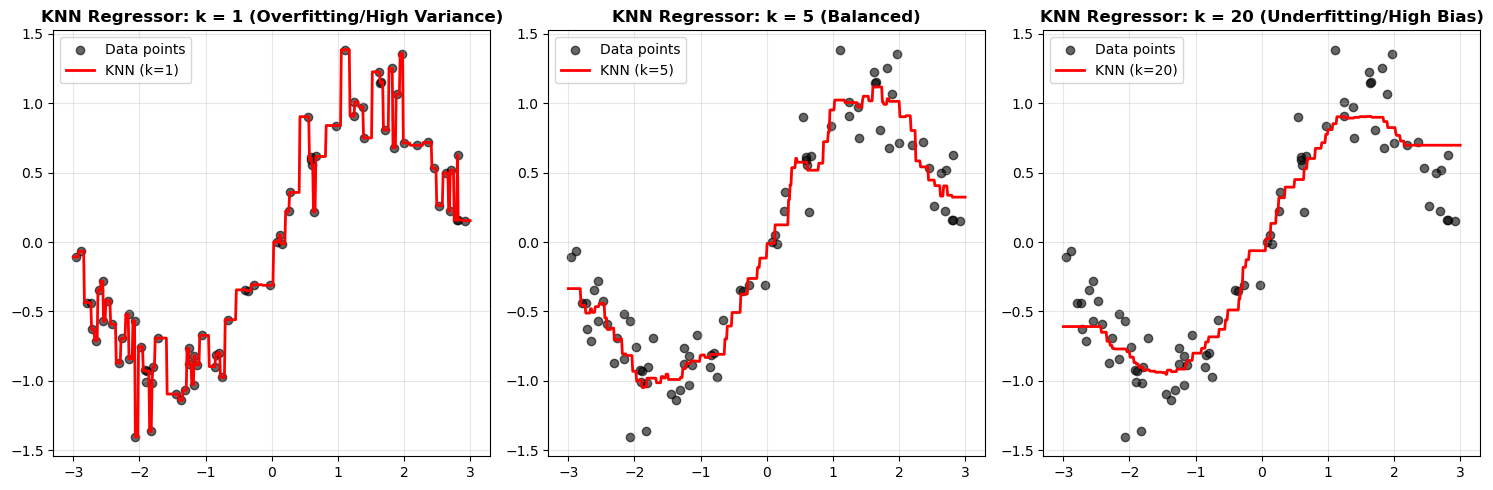

In [4]:
# Visualizing KNN Regression: Effect of k on Curve Smoothing
# Synthetic 1D non-linear relationship to observe how k affects the regression fit
np.random.seed(42)
X_synth = np.sort(np.random.uniform(-3, 3, size=(80, 1)), axis=0)
y_synth = np.sin(X_synth).ravel() + np.random.normal(0, 0.2, size=80)
X_synth_test = np.linspace(-3, 3, 500)[:, np.newaxis]

plt.figure(figsize=(15, 5))
for i, k in enumerate([1, 5, 20], 1):
    knr = KNeighborsRegressor(n_neighbors=k).fit(X_synth, y_synth)
    y_synth_pred = knr.predict(X_synth_test)
    
    plt.subplot(1, 3, i)
    plt.scatter(X_synth, y_synth, color='black', alpha=0.6, label='Data points')
    plt.plot(X_synth_test, y_synth_pred, color='red', linewidth=2, label=f'KNN (k={k})')
    plt.title(f'KNN Regressor: k = {k} ' + ('(Overfitting/High Variance)' if k==1 else '(Underfitting/High Bias)' if k==20 else '(Balanced)'), fontweight='bold')
    plt.legend()
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ====================================================================================
## 2️⃣ DECISION TREES: CLASSIFIER vs REGRESSOR
# ====================================================================================

### Mathematical Comparison:
| Concept | `DecisionTreeClassifier` | `DecisionTreeRegressor` |
|---|---|---|
| **Splitting Criterion** | **Gini Impurity**: $1 - \sum_{k} p_k^2$ <br> or **Entropy**: $-\sum_k p_k \log_2 p_k$ | **Mean Squared Error (Variance Reduction)**: $\text{MSE} = \frac{1}{|S|} \sum_{i \in S} (y_i - \bar{y}_S)^2$ <br> or **MAE**: $\frac{1}{|S|} \sum |y_i - \text{median}|$ |
| **Leaf Prediction** | **Class Mode** (majority vote) or class probabilities | **Sample Mean** $\bar{y} = \frac{1}{N_{\text{leaf}}} \sum y_i$ (or median) |
| **Prediction Shape** | Piecewise orthogonal hyperplanes (axis-aligned decision regions) | **Piecewise constant step-function** (approximates curve via discrete steps) |
| **Scaling Requirement** | **Not Required** (invariant to monotonic feature scaling) | **Not Required** |
| **Extrapolation** | Restricted to categorical training labels | **CANNOT EXTRAPOLATE**: If a test point has $X > X_{\max}$, the tree falls into the rightmost leaf and outputs the training leaf mean! |

In [5]:
# --- DECISION TREE CLASSIFIER --- 
dt_clf = DecisionTreeClassifier(max_depth=4, random_state=42)
dt_clf.fit(Xc_train_sc, yc_train)
y_pred_dt_c = dt_clf.predict(Xc_test_sc)

acc_dt = accuracy_score(yc_test, y_pred_dt_c)
f1_dt = f1_score(yc_test, y_pred_dt_c)
print(f"Decision Tree Classifier Accuracy: {acc_dt*100:.2f}%")
print(f"Decision Tree Classifier F1-Score: {f1_dt:.4f}")

# --- DECISION TREE REGRESSOR --- 
dt_reg = DecisionTreeRegressor(max_depth=4, random_state=42)
dt_reg.fit(Xr_train_sc, yr_train)
y_pred_dt_r = dt_reg.predict(Xr_test_sc)

r2_dt = r2_score(yr_test, y_pred_dt_r)
rmse_dt = np.sqrt(mean_squared_error(yr_test, y_pred_dt_r))
print(f"\nDecision Tree Regressor R2 Score:  {r2_dt:.4f}")
print(f"Decision Tree Regressor RMSE:      ${rmse_dt:,.2f}")

Decision Tree Classifier Accuracy: 77.72%
Decision Tree Classifier F1-Score: 0.8019

Decision Tree Regressor R2 Score:  0.8972
Decision Tree Regressor RMSE:      $4,345.88


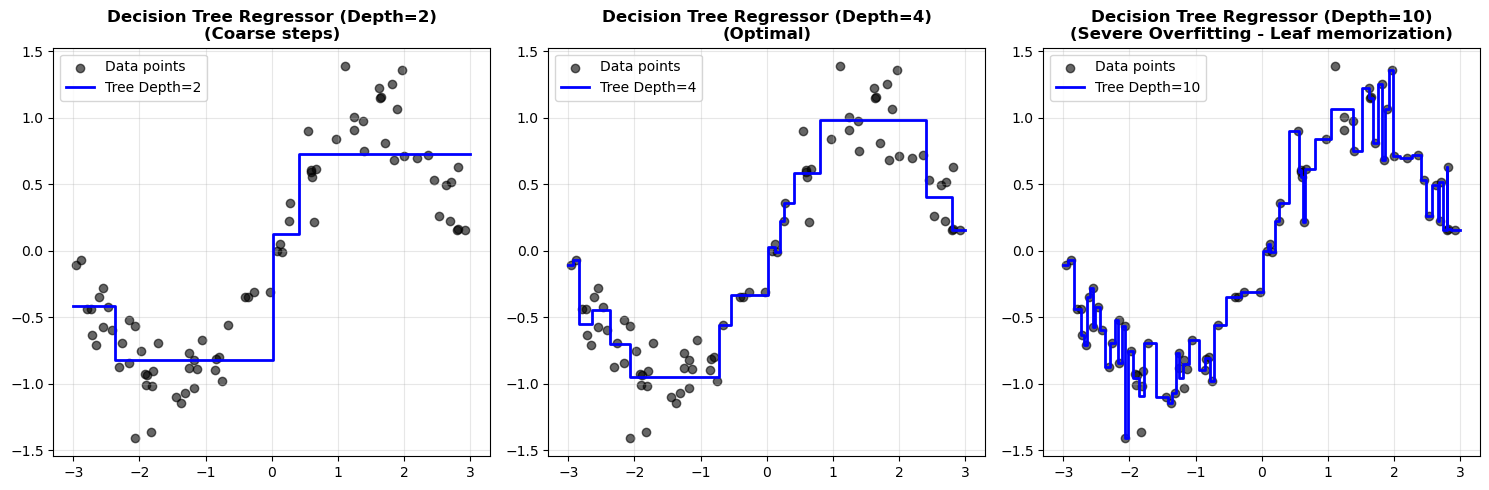

In [6]:
# Visualizing Decision Tree Regressor Step Function vs Depth
plt.figure(figsize=(15, 5))
for i, depth in enumerate([2, 4, 10], 1):
    dtr = DecisionTreeRegressor(max_depth=depth, random_state=42).fit(X_synth, y_synth)
    y_synth_dt = dtr.predict(X_synth_test)
    
    plt.subplot(1, 3, i)
    plt.scatter(X_synth, y_synth, color='black', alpha=0.6, label='Data points')
    plt.step(X_synth_test, y_synth_dt, color='blue', linewidth=2, label=f'Tree Depth={depth}')
    plt.title(f'Decision Tree Regressor (Depth={depth})\n' + ('(Coarse steps)' if depth==2 else '(Optimal)' if depth==4 else '(Severe Overfitting - Leaf memorization)'), fontweight='bold')
    plt.legend()
    plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ====================================================================================
## 3️⃣ SUPPORT VECTOR MACHINES: SVC vs SVR
# ====================================================================================

### Mathematical Comparison:
| Concept | Support Vector Classifier (`SVC`) | Support Vector Regressor (`SVR`) |
|---|---|---|
| **Objective** | **Maximize margin** $\frac{2}{\|w\|}$ between two hyperplane boundaries: $y_i(w^T x_i + b) \ge 1 - \xi_i$ | **Fit within $\epsilon$-insensitive tube**: Minimize $\frac{1}{2}\|w\|^2 + C \sum (\xi_i + \xi_i^*)$ subject to $|y_i - (w^T x_i + b)| \le \epsilon + \xi_i$ |
| **Penalty Zone** | Points falling inside the margin or misclassified incur penalty $\xi_i > 0$ | Errors smaller than $\epsilon$ have **zero loss**! Only points outside the tube incur penalty $\xi_i$ |
| **Support Vectors** | Points that lie exactly on the margin boundary or inside it | Points that lie **on or outside** the $\epsilon$-tube boundary |
| **Kernel Trick** | Linear, RBF (Gaussian), Polynomial, Sigmoid | Linear, RBF (Gaussian), Polynomial, Sigmoid |
| **Scaling Requirement** | **Mandatory** (kernel distances depend heavily on scale) | **Mandatory** |

In [7]:
# --- SUPPORT VECTOR CLASSIFIER (SVC) --- 
svc = SVC(kernel='rbf', C=1.0, random_state=42)
svc.fit(Xc_train_sc, yc_train)
y_pred_svc = svc.predict(Xc_test_sc)

acc_svc = accuracy_score(yc_test, y_pred_svc)
f1_svc = f1_score(yc_test, y_pred_svc)
print(f"Support Vector Classifier Accuracy: {acc_svc*100:.2f}%")
print(f"Support Vector Classifier F1-Score: {f1_svc:.4f}")

# --- SUPPORT VECTOR REGRESSOR (SVR) --- 
svr = SVR(kernel='rbf', C=1000, epsilon=0.1)
svr.fit(Xr_train_sc, yr_train)
y_pred_svr = svr.predict(Xr_test_sc)

r2_svr = r2_score(yr_test, y_pred_svr)
rmse_svr = np.sqrt(mean_squared_error(yr_test, y_pred_svr))
print(f"\nSupport Vector Regressor R2 Score:  {r2_svr:.4f}")
print(f"Support Vector Regressor RMSE:      ${rmse_svr:,.2f}")

Support Vector Classifier Accuracy: 85.87%
Support Vector Classifier F1-Score: 0.8750

Support Vector Regressor R2 Score:  0.7031
Support Vector Regressor RMSE:      $7,386.08


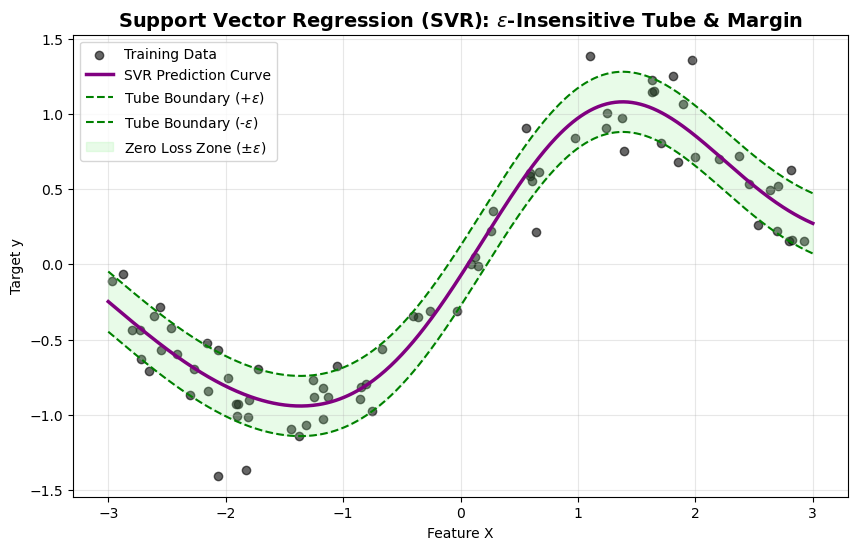

In [8]:
# Visualizing SVR with the Epsilon-Tube
svr_vis = SVR(kernel='rbf', C=10, epsilon=0.2).fit(X_synth, y_synth)
y_synth_svr = svr_vis.predict(X_synth_test)

plt.figure(figsize=(10, 6))
plt.scatter(X_synth, y_synth, color='black', alpha=0.6, label='Training Data')
plt.plot(X_synth_test, y_synth_svr, color='purple', linewidth=2.5, label='SVR Prediction Curve')
plt.plot(X_synth_test, y_synth_svr + 0.2, color='green', linestyle='--', linewidth=1.5, label=r'Tube Boundary (+$\epsilon$)')
plt.plot(X_synth_test, y_synth_svr - 0.2, color='green', linestyle='--', linewidth=1.5, label=r'Tube Boundary (-$\epsilon$)')
plt.fill_between(X_synth_test.ravel(), y_synth_svr - 0.2, y_synth_svr + 0.2, color='lightgreen', alpha=0.2, label=r'Zero Loss Zone ($\pm \epsilon$)')
plt.title(r'Support Vector Regression (SVR): $\epsilon$-Insensitive Tube & Margin', fontsize=14, fontweight='bold')
plt.xlabel('Feature X')
plt.ylabel('Target y')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ====================================================================================
## 4️⃣ ENSEMBLE METHODS: RANDOM FOREST & GRADIENT BOOSTING
# ====================================================================================

### Random Forest (Bagging):
- **Classifier**: Ensembles $B$ decision trees trained on bootstrap samples with random feature subsets. Prediction = **Majority Vote**.
- **Regressor**: Ensembles $B$ decision trees. Prediction = **Average of all trees**: $\hat{y} = \frac{1}{B} \sum_{b=1}^B T_b(x)$. Drastically smooths out the jagged step-function of individual decision trees!
- **📦 Out-Of-Bag (OOB) Evaluation**:
  - Each bootstrap sample leaves out $\approx 36.8\%$ of training observations ($P(\text{OOB}) = (1 - 1/n)^n \to 1/e$).
  - For each sample, predictions are made using **only** trees where that sample was out-of-bag.
  - **Classifier**: Computes unbiased OOB Accuracy & OOB Class Probabilities.
  - **Regressor**: Computes unbiased OOB $R^2$ Score.
  - Eliminates the need for a separate validation split or $K$-fold cross-validation!

### Gradient Boosting (Boosting):
- **Classifier**: Fits trees sequentially to minimize Logistic Loss (Log-Loss / Cross-Entropy) via negative gradient residuals in probability space.
- **Regressor**: Fits trees sequentially to minimize Squared Error Loss: each tree predicts the **pseudo-residuals** $r_i = y_i - \hat{y}_i^{(m-1)}$ with shrinkage learning rate $\eta$.


In [9]:
# --- RANDOM FOREST & GRADIENT BOOSTING CLASSIFIERS --- 
rf_clf = RandomForestClassifier(n_estimators=100, max_depth=5, oob_score=True, random_state=42).fit(Xc_train_sc, yc_train)
gb_clf = GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42).fit(Xc_train_sc, yc_train)

acc_rf = accuracy_score(yc_test, rf_clf.predict(Xc_test_sc))
acc_gb = accuracy_score(yc_test, gb_clf.predict(Xc_test_sc))
print(f"Random Forest Classifier Accuracy:      {acc_rf*100:.2f}% (OOB Score: {rf_clf.oob_score_*100:.2f}%)")
print(f"Gradient Boosting Classifier Accuracy:  {acc_gb*100:.2f}%")

# --- RANDOM FOREST & GRADIENT BOOSTING REGRESSORS --- 
rf_reg = RandomForestRegressor(n_estimators=100, max_depth=5, oob_score=True, random_state=42).fit(Xr_train_sc, yr_train)
gb_reg = GradientBoostingRegressor(n_estimators=100, max_depth=3, random_state=42).fit(Xr_train_sc, yr_train)

r2_rf = r2_score(yr_test, rf_reg.predict(Xr_test_sc))
r2_gb = r2_score(yr_test, gb_reg.predict(Xr_test_sc))
rmse_rf = np.sqrt(mean_squared_error(yr_test, rf_reg.predict(Xr_test_sc)))
rmse_gb = np.sqrt(mean_squared_error(yr_test, gb_reg.predict(Xr_test_sc)))

print(f"\nRandom Forest Regressor R2 Score:      {r2_rf:.4f} (OOB R2: {rf_reg.oob_score_:.4f})  |  RMSE: ${rmse_rf:,.2f}")
print(f"Gradient Boosting Regressor R2 Score:  {r2_gb:.4f}  |  RMSE: ${rmse_gb:,.2f}")


Random Forest Classifier Accuracy:      85.33% (OOB Score: 84.74%)
Gradient Boosting Classifier Accuracy:  88.04%



Random Forest Regressor R2 Score:      0.9016 (OOB R2: 0.8427)  |  RMSE: $4,251.25
Gradient Boosting Regressor R2 Score:  0.9009  |  RMSE: $4,268.28


# ====================================================================================
## 5️⃣ MASTER BENCHMARK & COMPARISON MATRIX
# ====================================================================================
Side-by-side performance comparison of all dual-purpose algorithms on identical classification and regression datasets.

In [10]:
# Helper function to compute classification metrics including Selectivity
def get_clf_scores(clf, X_test, y_test):
    preds = clf.predict(X_test)
    cm = confusion_matrix(y_test, preds)
    tn, fp, fn, tp = cm.ravel()
    acc = accuracy_score(y_test, preds)
    prec = precision_score(y_test, preds)
    rec = recall_score(y_test, preds)
    selectivity = tn / (tn + fp)
    f1 = f1_score(y_test, preds)
    return f"{acc*100:.2f}%", f"{selectivity:.4f}", f"{f1:.4f}"

acc_k, sel_k, f1_k = get_clf_scores(knn_clf, Xc_test_sc, yc_test)
acc_d, sel_d, f1_d = get_clf_scores(dt_clf, Xc_test_sc, yc_test)
acc_s, sel_s, f1_s = get_clf_scores(svc, Xc_test_sc, yc_test)
acc_r, sel_r, f1_r = get_clf_scores(rf_clf, Xc_test_sc, yc_test)
acc_g, sel_g, f1_g = get_clf_scores(gb_clf, Xc_test_sc, yc_test)

master_benchmark = pd.DataFrame({
    'Algorithm': ['KNN', 'Decision Tree', 'Support Vector Machine', 'Random Forest', 'Gradient Boosting'],
    'Accuracy': [acc_k, acc_d, acc_s, acc_r, acc_g],
    'Selectivity (TN/(TN+FP))': [sel_k, sel_d, sel_s, sel_r, sel_g],
    'F1-Score': [f1_k, f1_d, f1_s, f1_r, f1_g],
    'Regression R2': [f"{r2_knn:.4f}", f"{r2_dt:.4f}", f"{r2_svr:.4f}", f"{r2_rf:.4f}", f"{r2_gb:.4f}"],
    'Regression RMSE': [f"${rmse_knn:,.2f}", f"${rmse_dt:,.2f}", f"${rmse_svr:,.2f}", f"${rmse_rf:,.2f}", f"${rmse_gb:,.2f}"]
})

print("=== MASTER ALGORITHM BENCHMARK WITH SELECTIVITY & REGRESSION METRICS ===")
display(master_benchmark)

=== MASTER ALGORITHM BENCHMARK WITH SELECTIVITY & REGRESSION METRICS ===


,Algorithm,Accuracy,Selectivity (TN/(TN+FP)),F1-Score,Regression R2,Regression RMSE
0,KNN,89.67%,0.8780,0.9073,0.8315,"$5,564.59"
1,Decision Tree,77.72%,0.7317,0.8019,0.8972,"$4,345.88"
2,Support Vector Machine,85.87%,0.8171,0.8750,0.7031,"$7,386.08"
3,Random Forest,85.33%,0.8293,0.8683,0.9016,"$4,251.25"
4,Gradient Boosting,88.04%,0.8659,0.8922,0.9009,"$4,268.28"


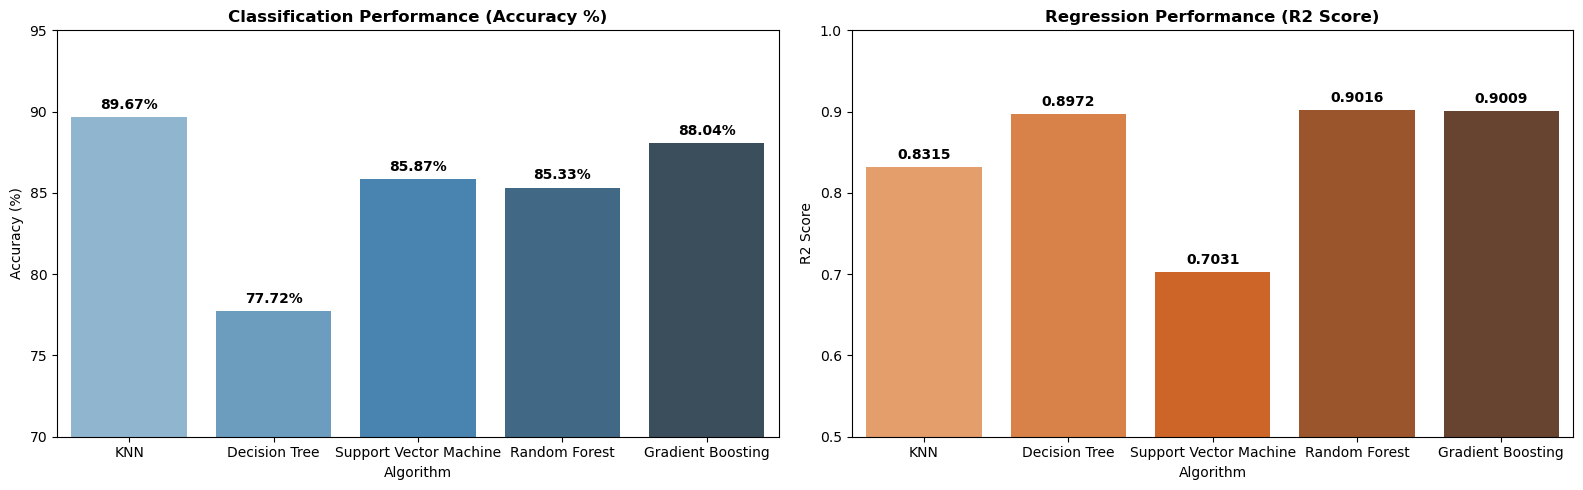

In [11]:
# Visualizing Classification vs Regression Comparison
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Accuracy plot
acc_values = [acc_knn*100, acc_dt*100, acc_svc*100, acc_rf*100, acc_gb*100]
sns.barplot(x=master_benchmark['Algorithm'], y=acc_values, ax=axes[0], palette='Blues_d')
axes[0].set_title('Classification Performance (Accuracy %)', fontweight='bold')
axes[0].set_ylabel('Accuracy (%)')
axes[0].set_ylim(70, 95)
for i, v in enumerate(acc_values):
    axes[0].text(i, v + 0.5, f"{v:.2f}%", ha='center', fontweight='bold')

# R2 plot
r2_values = [r2_knn, r2_dt, r2_svr, r2_rf, r2_gb]
sns.barplot(x=master_benchmark['Algorithm'], y=r2_values, ax=axes[1], palette='Oranges_d')
axes[1].set_title('Regression Performance (R2 Score)', fontweight='bold')
axes[1].set_ylabel('R2 Score')
axes[1].set_ylim(0.5, 1.0)
for i, v in enumerate(r2_values):
    axes[1].text(i, v + 0.01, f"{v:.4f}", ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

# ====================================================================================
## 6️⃣ TOP 25 MACHINE LEARNING INTERVIEW QUESTIONS & ANSWERS
# ====================================================================================

| # | Question | Comprehensive Interview-Grade Answer |
|---|---|---|
| **1** | **Can Decision Tree or Random Forest Regressors extrapolate outside the training range?** | **NO.** In tree-based regression, predictions at leaf nodes are sample averages of training points. If test input $x$ is beyond the range seen during training, it simply falls into the outermost leaf, outputting a constant value bounded by $[\min(y_{\text{train}}), \max(y_{\text{train}})]$. For extrapolation, use Linear Regression, Polynomials, or neural networks. |
| **2** | **How does the split criterion differ between DecisionTree Classifier and Regressor?** | Classifier uses **Gini Impurity** ($1 - \sum p_k^2$) or **Entropy** ($-\sum p_k \log_2 p_k$) to maximize information gain (purity). Regressor uses **Mean Squared Error** (variance reduction: $\text{MSE}_T - \frac{N_L}{N}\text{MSE}_L - \frac{N_R}{N}\text{MSE}_R$) or **MAE** to minimize variance within child partitions. |
| **3** | **How does KNN predict in classification vs regression?** | In classification, KNN uses **majority voting** among the $k$ nearest neighbors (or distance-weighted vote counts). In regression, KNN outputs the **mean** (or inverse-distance weighted average) of the $k$ neighbor continuous target values. |
| **4** | **What is the Curse of Dimensionality and how does it cripple KNN?** | As the number of dimensions $d$ grows, volume of space grows exponentially ($V \propto r^d$). Points become equidistant from each other (ratio of distance to nearest neighbor vs furthest neighbor approaches 1). KNN loses discriminative power, and computation cost scales as $O(d \cdot n)$. |
| **5** | **How does SVR achieve sparsity while Ridge Regression does not?** | SVR uses Vapnik's $\epsilon$-insensitive loss function: points whose absolute error is less than $\epsilon$ have exactly zero loss. Only points on or outside the $\pm \epsilon$ boundary become **Support Vectors** (their Lagrange multipliers $\alpha_i, \alpha_i^* > 0$). Points strictly inside the tube have $\alpha_i = 0$, producing a sparse solution. |
| **6** | **What is the geometric meaning of the $\epsilon$-tube in SVR?** | The $\epsilon$-tube defines a margin around the regression prediction line where deviations are tolerated without penalty. It acts as an envelope of insensitivity, making SVR robust against small noise in target values. |
| **7** | **Why is feature scaling mandatory for KNN and SVM, but optional for Trees?** | KNN and SVM compute Euclidean or kernel distances in vector space ($d(x_1, x_2) = \sqrt{\sum (x_{1i} - x_{2i})^2}$). A feature with range $[0, 10000]$ would completely dominate a feature with range $[0, 1]$. Trees only evaluate ordered thresholds ($x_j \le \theta$) along one feature axis at a time, making them invariant to monotonic scaling. |
| **8** | **How does the value of $k$ in KNN affect the Bias-Variance tradeoff?** | Small $k$ (e.g. $k=1$): Fits training noise perfectly $\implies$ **Low Bias, High Variance** (Overfitting). Large $k$ (e.g. $k=n$): Predicts majority class or global mean $\implies$ **High Bias, Low Variance** (Underfitting). |
| **9** | **What is Cost-Complexity Pruning (ccp_alpha) in Decision Trees?** | Post-pruning technique that minimizes cost function $R_\alpha(T) = R(T) + \alpha |T|$ where $R(T)$ is total tree misclassification/error and $|T|$ is number of terminal leaves. Increasing $\alpha$ penalizes complex trees, pruning subtrees that contribute minimal error reduction. |
| **10** | **Why does Random Forest reduce variance without increasing bias?** | Bagging trains $B$ independent trees on bootstrap samples. If individual trees have variance $\sigma^2$ and pairwise correlation $\rho$, ensemble variance is $\rho \sigma^2 + \frac{1-\rho}{B}\sigma^2$. Random feature subsampling reduces inter-tree correlation $\rho$, dramatically shrinking variance while preserving low individual tree bias. |
| **11** | **What is Out-Of-Bag (OOB) error in Random Forest?** | In bootstrapping with replacement, each sample has a probability $(1 - 1/n)^n \approx e^{-1} \approx 36.8\%$ of NOT being selected for a tree. These unselected samples act as a built-in validation set (OOB samples). Testing each tree on its OOB points provides an unbiased generalization estimate without separate cross-validation. |
| **12** | **How does Gradient Boosting differ from AdaBoost?** | AdaBoost increases sample weights of previously misclassified points. Gradient Boosting formulates boosting as gradient descent in function space: each subsequent tree is explicitly fit to the **negative gradient (pseudo-residuals)** of the chosen differentiable loss function. |
| **13** | **What is the Kernel Trick in SVM?** | It implicitly maps data from low-dimensional non-linear input space into a high-dimensional (or infinite-dimensional) feature space where classes are linearly separable, without ever explicitly computing coordinate transformations: $K(x, z) = \langle \phi(x), \phi(z) \rangle$. |
| **14** | **What is the effect of SVM hyperparameters $C$ and $\gamma$ (gamma)?** | Large $C$: Heavy penalty for violations $\implies$ narrower margin, risk of overfitting. Small $C$: Tolerates violations $\implies$ wider margin, higher bias. Large $\gamma$: RBF kernel has narrow bell-curve $\implies$ support vectors have local influence (overfitting). Small $\gamma$: Wide bell-curve $\implies$ global smooth boundaries. |
| **15** | **When should you prefer Precision over Recall, and vice-versa?** | Prefer **Precision** when False Positives are costly (e.g. Spam detection where marking important email as spam is unacceptable). Prefer **Recall** when False Negatives are fatal (e.g. Cancer detection, fraud detection where missing a true case is catastrophic). |
| **16** | **What is the difference between ROC-AUC and PR-AUC?** | ROC plots True Positive Rate vs False Positive Rate. On highly imbalanced datasets, FPR stays deceptively low because the negative class is massive. PR Curve (Precision vs Recall) focuses strictly on the minority positive class, providing an honest evaluation for severe class imbalance. |
| **17** | **What is Log-Loss (Cross-Entropy Loss)?** | $\mathcal{L} = -\frac{1}{n} \sum [y_i \log(\hat{p}_i) + (1-y_i) \log(1-\hat{p}_i)]$. It heavily penalizes confident wrong predictions (e.g. predicting $\hat{p}=0.01$ when true class is 1 yields $\log(0.01) \approx -4.6$). |
| **18** | **Can Logistic Regression be used for Regression?** | **No.** Despite its name, Logistic Regression is a classification algorithm. It outputs probabilities $p \in [0, 1]$ via the sigmoid function $\sigma(z) = \frac{1}{1 + e^{-z}}$ and optimizes log-likelihood (cross-entropy), not continuous regression targets. |
| **19** | **Why does an unpruned Decision Tree have 0 training error?** | If allowed to grow indefinitely (`max_depth=None`), the tree can split until every leaf contains a single training sample ($N_{\text{leaf}} = 1$), memorizing training data and achieving 100% accuracy / 0 MSE, but suffering from catastrophic overfitting. |
| **20** | **How do you handle multi-class classification in binary classifiers like SVM?** | Two strategies: (1) **One-vs-Rest (OvR)**: Train $K$ classifiers, each distinguishing class $k$ from all other $K-1$ classes combined. (2) **One-vs-One (OvO)**: Train $\frac{K(K-1)}{2}$ binary classifiers for every pair of classes; winner chosen by majority vote (scikit-learn `SVC` uses OvO). |
| **21** | **What is the difference between bagging and boosting in bias-variance terms?** | **Bagging** reduces variance by averaging low-bias, high-variance base learners (deep trees). **Boosting** reduces bias by sequentially combining high-bias, weak base learners (shallow trees/stumps) to form a strong learner. |
| **22** | **Why does Random Forest feature importance favor high-cardinality features?** | In Gini importance (MDI), continuous features or categorical features with many unique levels have many more potential split points, giving them more opportunities to reduce impurity purely by random chance. Fix: Use Permutation Importance. |
| **23** | **What is Early Stopping in Gradient Boosting?** | Monitoring validation set loss at each boosting iteration $m$. If validation loss stops improving for $k$ consecutive rounds (tolerance/patience), training terminates, preventing overfitting. |
| **24** | **How does Weighted KNN work?** | Instead of giving equal voting weight $\frac{1}{k}$, each neighbor $x_i$ receives weight inversely proportional to its Euclidean distance: $w_i = \frac{1}{d(x, x_i)^2}$. Closer neighbors have significantly higher influence on prediction. |
| **25** | **What are the time complexities of KNN at train vs test time?** | Training time: $O(1)$ (KNN is a lazy learner; simply stores data). Test / Query time: $O(n \cdot d)$ brute force, or $O(d \log n)$ with KD-Trees/Ball-Trees. This makes KNN very fast to train but computationally slow and memory-intensive in production. |